In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cố định seed cho toàn bộ notebook
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

# Đọc dữ liệu với dấu phân cách ;
df = pd.read_csv("../data/raw/bank-additional-full.csv", sep=";")

print("Kích thước dữ liệu (dòng, cột):", df.shape)
print("\n--- Tỷ lệ phân bố nhãn y ---")
print(df['y'].value_counts(normalize=True).round(4) * 100)
print("\n--- Thông tin kiểu dữ liệu và giá trị thiếu ---")
df.info()

Kích thước dữ liệu (dòng, cột): (41188, 21)

--- Tỷ lệ phân bố nhãn y ---
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

--- Thông tin kiểu dữ liệu và giá trị thiếu ---
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64 

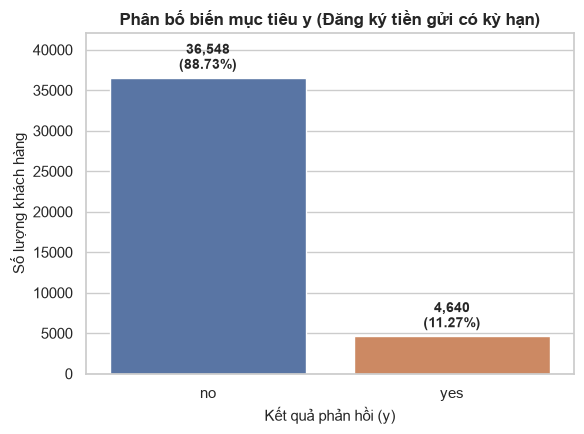

In [19]:
import os
os.makedirs("../reports/figures", exist_ok=True)

# 1. Phân bố biến mục tiêu y
fig, ax = plt.subplots(figsize=(6, 4.5))
counts = df['y'].value_counts()
pcts = df['y'].value_counts(normalize=True) * 100

bars = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
ax.set_title("Phân bố biến mục tiêu y (Đăng ký tiền gửi có kỳ hạn)", fontsize=12, fontweight='bold')
ax.set_xlabel("Kết quả phản hồi (y)", fontsize=11)
ax.set_ylabel("Số lượng khách hàng", fontsize=11)
ax.set_ylim(0, counts.max() * 1.15)

for bar, count, pct in zip(bars.patches, counts.values, pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 600,
            f"{count:,}\n({pct:.2f}%)", ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig("../reports/figures/01_target_distribution.png", dpi=300)
plt.show()

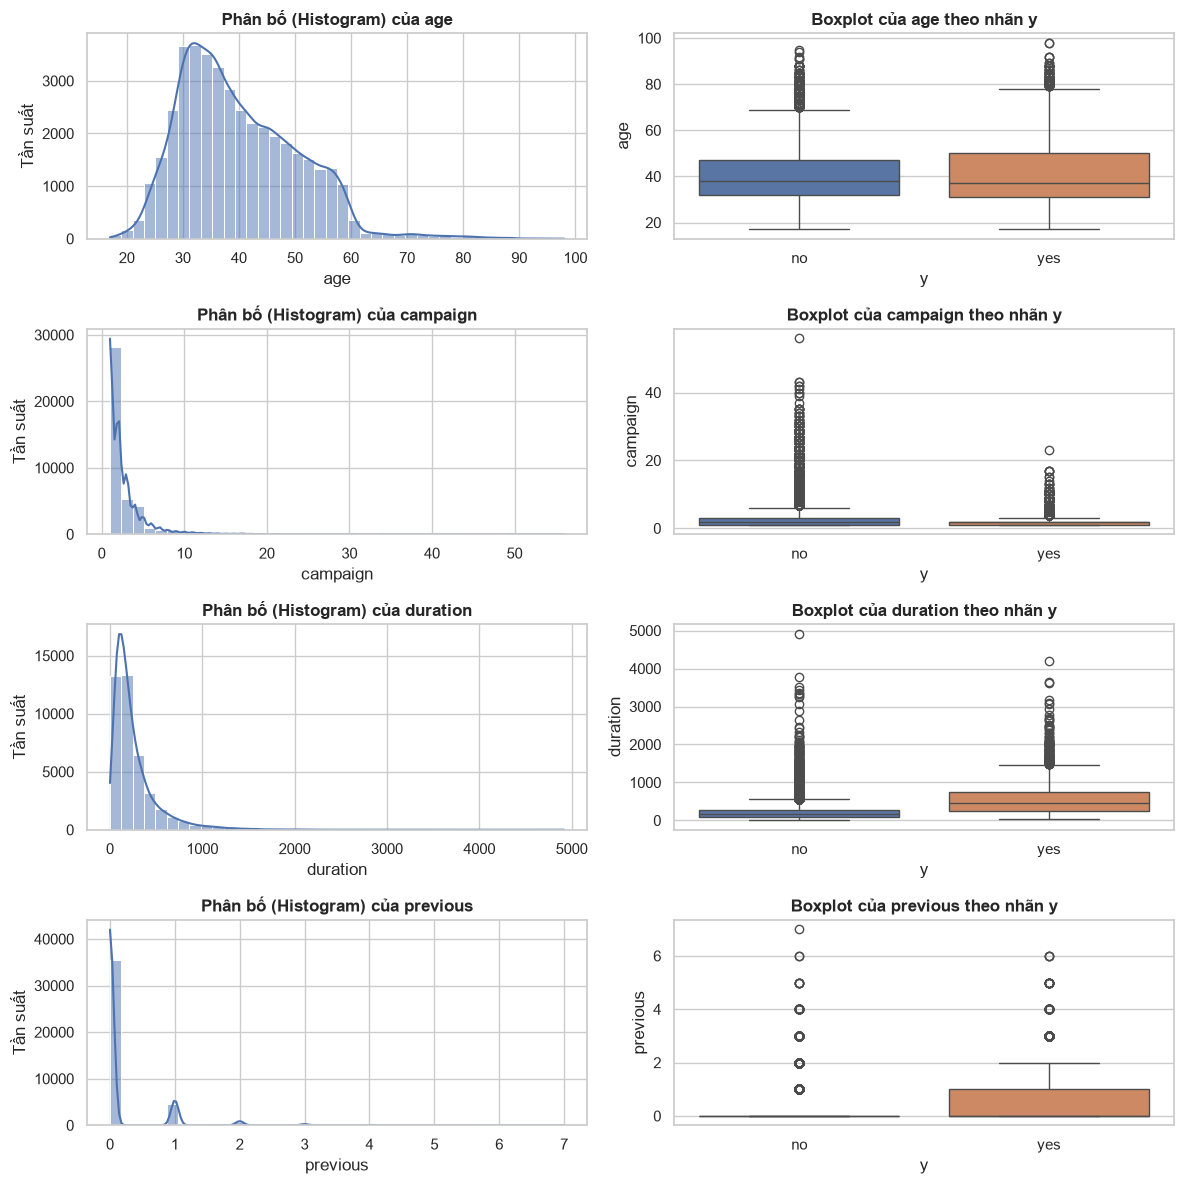

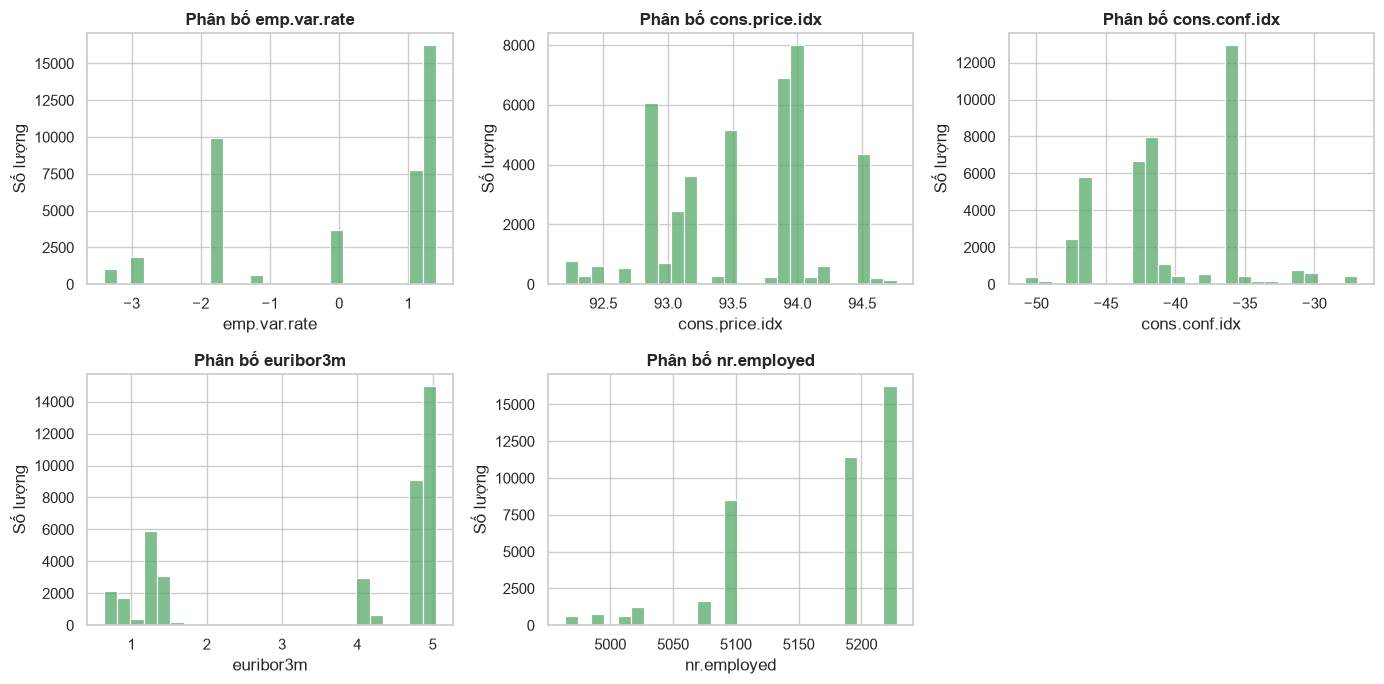

In [20]:
# 2A. Histogram và Boxplot cho nhóm biến khách hàng & chiến dịch
cust_num_cols = ['age', 'campaign', 'duration', 'previous']
fig, axes = plt.subplots(len(cust_num_cols), 2, figsize=(12, 12))

for i, col in enumerate(cust_num_cols):
    # Histogram
    sns.histplot(df[col], bins=40, kde=True, ax=axes[i, 0], color="#4C72B0")
    axes[i, 0].set_title(f"Phân bố (Histogram) của {col}", fontweight='bold')
    axes[i, 0].set_ylabel("Tần suất")
    
    # Boxplot theo nhãn y
    sns.boxplot(data=df, x='y', y=col, hue='y', palette=["#4C72B0", "#DD8452"], legend=False, ax=axes[i, 1])
    axes[i, 1].set_title(f"Boxplot của {col} theo nhãn y", fontweight='bold')

plt.tight_layout()
plt.savefig("../reports/figures/02a_numeric_customer_dist.png", dpi=300)
plt.show()

# 2B. Histogram cho các chỉ số kinh tế vĩ mô
macro_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(macro_cols):
    sns.histplot(df[col], bins=25, kde=False, ax=axes[i], color="#55A868")
    axes[i].set_title(f"Phân bố {col}", fontweight='bold')
    axes[i].set_ylabel("Số lượng")

axes[-1].axis('off') # Ẩn ô thừa thứ 6
plt.tight_layout()
plt.savefig("../reports/figures/02b_macro_economic_dist.png", dpi=300)
plt.show()

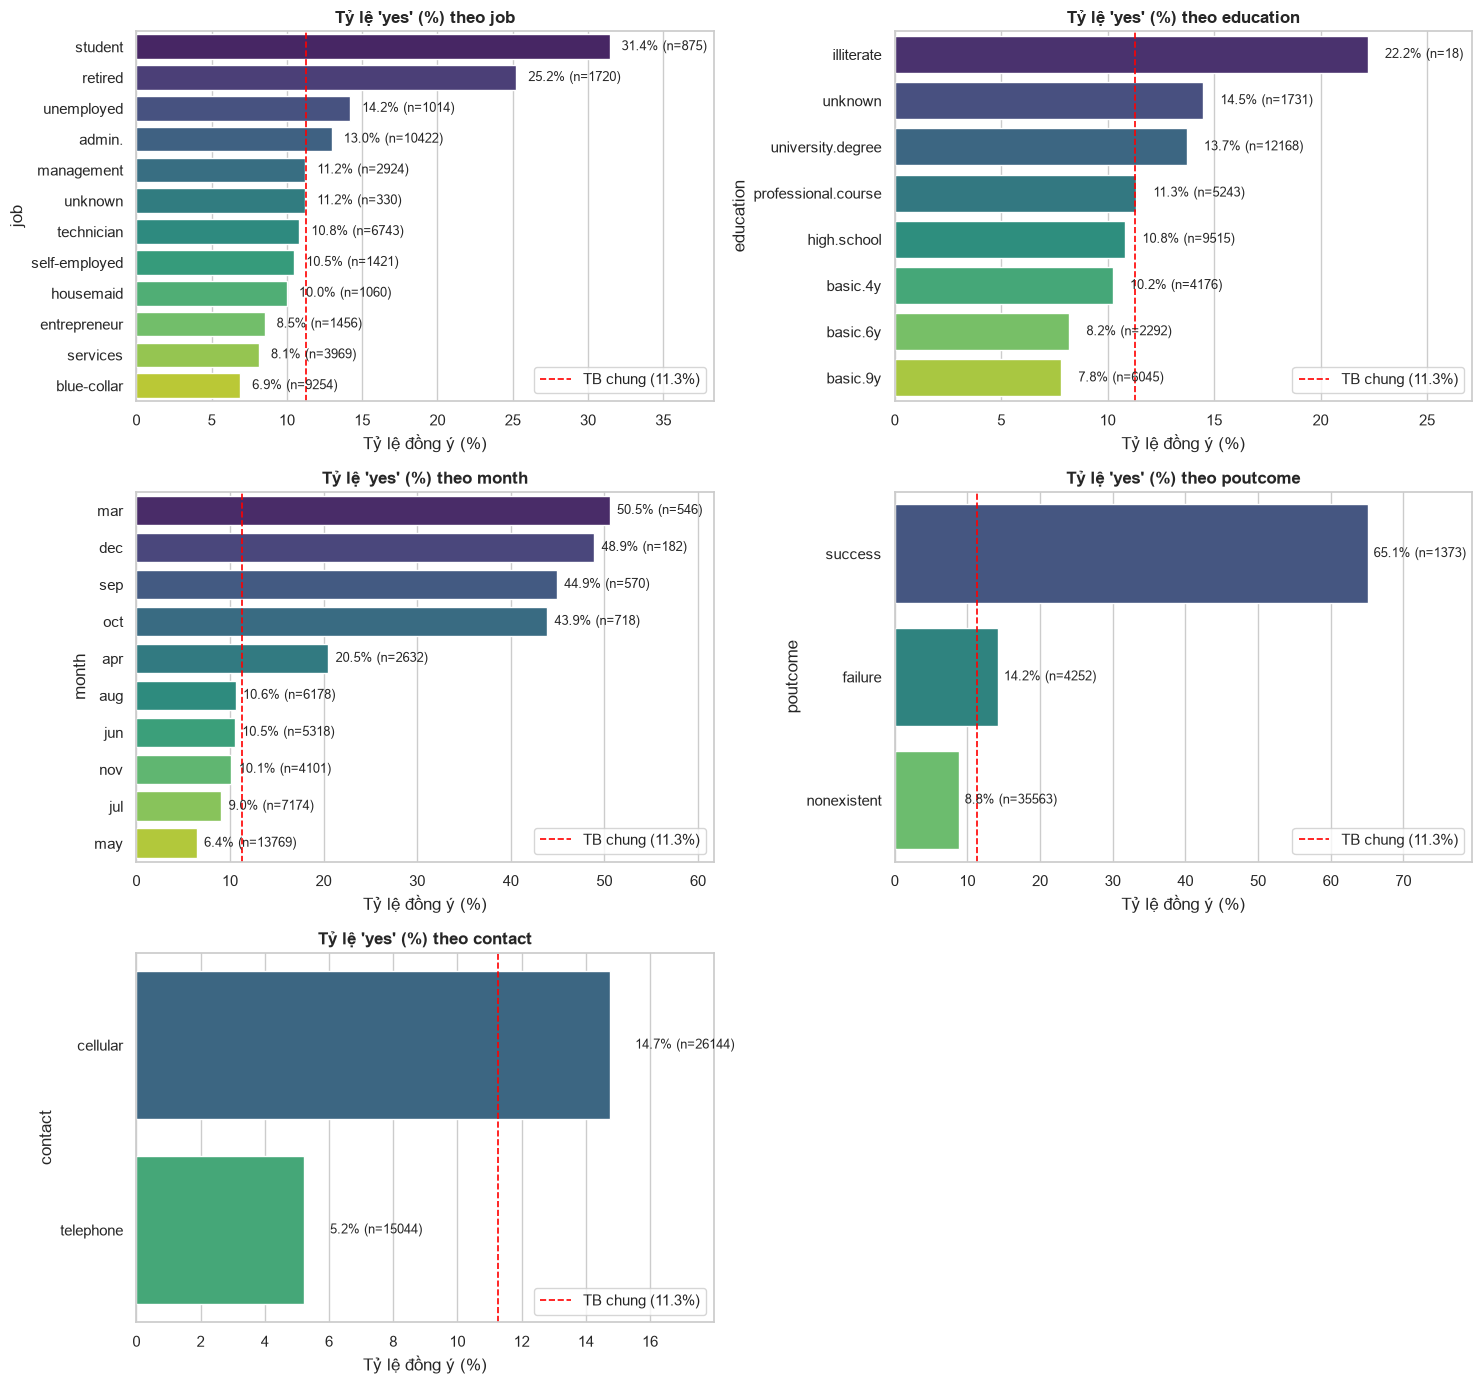

In [21]:
# 3. Tỷ lệ đăng ký ('yes') theo các biến phân loại chính
df['y_bin'] = (df['y'] == 'yes').astype(int)
cat_cols = ['job', 'education', 'month', 'poutcome', 'contact']

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()
overall_rate = df['y_bin'].mean() * 100

for i, col in enumerate(cat_cols):
    summary = df.groupby(col)['y_bin'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)
    summary['rate'] = summary['mean'] * 100
    
    sns.barplot(x=summary['rate'], y=summary.index, hue=summary.index, palette="viridis", legend=False, ax=axes[i])
    axes[i].axvline(overall_rate, color='red', linestyle='--', linewidth=1.2, label=f'TB chung ({overall_rate:.1f}%)')
    axes[i].set_title(f"Tỷ lệ 'yes' (%) theo {col}", fontweight='bold')
    axes[i].set_xlabel("Tỷ lệ đồng ý (%)")
    axes[i].set_xlim(0, summary['rate'].max() * 1.22)
    axes[i].legend(loc='lower right')
    
    for p, (_, row) in zip(axes[i].patches, summary.iterrows()):
        axes[i].text(p.get_width() + 0.8, p.get_y() + p.get_height()/2,
                     f"{row['rate']:.1f}% (n={int(row['count'])})", va='center', fontsize=9)

axes[-1].axis('off')
plt.tight_layout()
plt.savefig("../reports/figures/03_categorical_yes_rate.png", dpi=300)
plt.show()

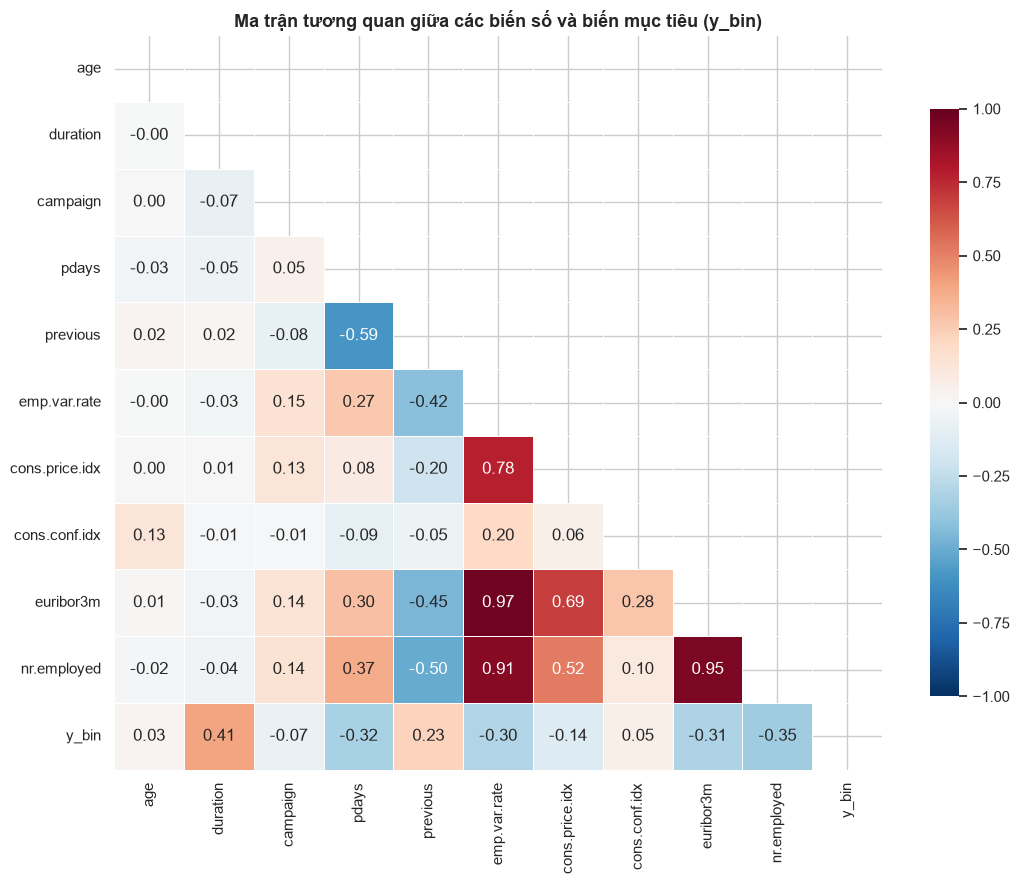

In [22]:
# 4. Ma trận tương quan Pearson giữa các biến số
num_all = ['age', 'duration', 'campaign', 'pdays', 'previous', 
           'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y_bin']

plt.figure(figsize=(11, 9))
corr_matrix = df[num_all].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Che nửa trên cho dễ nhìn

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Ma trận tương quan giữa các biến số và biến mục tiêu (y_bin)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("../reports/figures/04_correlation_matrix.png", dpi=300)
plt.show()

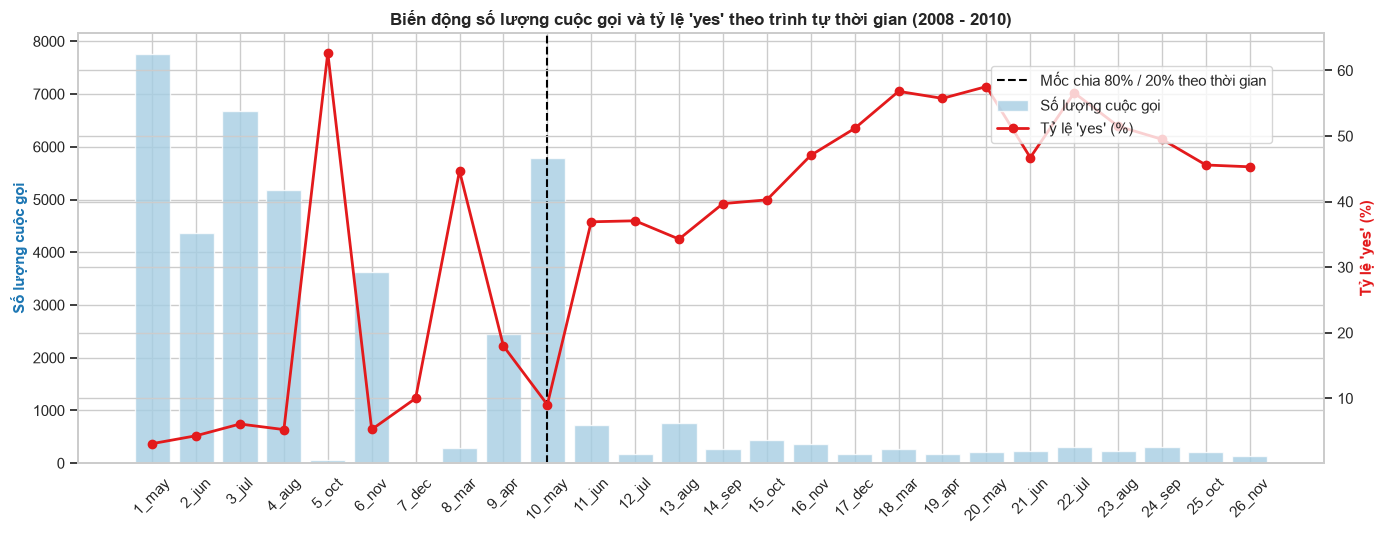

In [23]:
# 5. Phân tích xu hướng tỷ lệ 'yes' và số lượng cuộc gọi theo trình tự thời gian
# Xác định mỗi lần cột 'month' đổi giá trị là một đợt/tháng mới theo dòng thời gian
df['time_period'] = (df['month'] != df['month'].shift()).cumsum()
period_summary = df.groupby(['time_period', 'month'], sort=False)['y_bin'].agg(
    total_calls='count',
    yes_rate=lambda x: x.mean() * 100
).reset_index()
period_summary['label'] = period_summary['time_period'].astype(str) + "_" + period_summary['month']

fig, ax1 = plt.subplots(figsize=(14, 5.5))

# Biểu đồ cột: Số lượng cuộc gọi
bars = ax1.bar(period_summary['label'], period_summary['total_calls'], color="#A6CEE3", alpha=0.8, label="Số lượng cuộc gọi")
ax1.set_ylabel("Số lượng cuộc gọi", color="#1F78B4", fontsize=11, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

# Trục tung thứ 2: Đường tỷ lệ 'yes' (%)
ax2 = ax1.twinx()
ax2.plot(period_summary['label'], period_summary['yes_rate'], color="#E31A1C", marker='o', linewidth=2, label="Tỷ lệ 'yes' (%)")
ax2.set_ylabel("Tỷ lệ 'yes' (%)", color="#E31A1C", fontsize=11, fontweight='bold')

# Vẽ đường đánh dấu mốc cắt 80% dữ liệu đầu (nếu chia theo thời gian)
split_period = df.iloc[int(len(df)*0.8)]['time_period']
split_idx_plot = period_summary[period_summary['time_period'] == split_period].index[0]
ax1.axvline(split_idx_plot, color='black', linestyle='--', linewidth=1.5, label="Mốc chia 80% / 20% theo thời gian")

plt.title("Biến động số lượng cuộc gọi và tỷ lệ 'yes' theo trình tự thời gian (2008 - 2010)", fontsize=12, fontweight='bold')
fig.legend(loc="upper right", bbox_to_anchor=(0.92, 0.88))
plt.tight_layout()
plt.savefig("../reports/figures/05_time_series_trend.png", dpi=300)
plt.show()

In [24]:
# 1. Tạo bản sao làm sạch từ dữ liệu gốc (loại bỏ các cột tạm thời đã tạo ở bước EDA nếu có)
cols_to_drop_temp = [c for c in ['y_bin', 'time_period'] if c in df.columns]
df_clean = df.drop(columns=cols_to_drop_temp).copy()

# 2. Kiểm tra và đếm giá trị 'unknown' ở 6 cột phân loại
unknown_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan']
unknown_summary = []

for col in unknown_cols:
    count_unk = (df_clean[col] == 'unknown').sum()
    pct_unk = (count_unk / len(df_clean)) * 100
    unknown_summary.append({
        'Cột': col,
        'Số lượng unknown': count_unk,
        'Tỷ lệ (%)': round(pct_unk, 2)
    })

df_unknown_report = pd.DataFrame(unknown_summary)
print("--- THỐNG KÊ GIÁ TRỊ 'UNKNOWN' ---")
display(df_unknown_report)

# 3. Kiểm tra dòng trùng lặp
dup_count = df_clean.duplicated().sum()
print(f"\nSố dòng trùng lặp hoàn toàn trong dữ liệu: {dup_count}")

--- THỐNG KÊ GIÁ TRỊ 'UNKNOWN' ---


,Cột,Số lượng unknown,Tỷ lệ (%)
0,job,330,0.80
1,marital,80,0.19
2,education,1731,4.20
3,default,8597,20.87
4,housing,990,2.40
5,loan,990,2.40



Số dòng trùng lặp hoàn toàn trong dữ liệu: 12


In [25]:
import os
import joblib

# Tạo bản sao làm sạch từ dữ liệu gốc
cols_to_drop_temp = [c for c in ['y_bin', 'time_period'] if c in df.columns]
df_clean = df.drop(columns=cols_to_drop_temp).copy()

# 1. Loại bỏ 12 dòng trùng lặp hoàn toàn
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# 2. Kiểm tra mâu thuẫn giữa pdays != 999 với previous > 0 và poutcome
print("--- KIỂM TRA CHÉO pdays != 999 VỚI previous > 0 ---")
print(pd.crosstab(df_clean['previous'] > 0, df_clean['pdays'] != 999, 
                  rownames=['previous > 0'], colnames=['pdays != 999']))

print("\n--- KIỂM TRA CHÉO pdays != 999 VỚI poutcome ---")
print(pd.crosstab(df_clean['poutcome'], df_clean['pdays'] != 999, 
                  colnames=['pdays != 999']))

# 3. Bằng chứng tỷ lệ 'yes' theo trạng thái nợ xấu (default)
print("\n--- TỶ LỆ ĐĂNG KÝ ('yes') THEO TRẠNG THÁI DEFAULT ---")
default_evidence = df_clean.assign(y_bin=(df_clean['y'] == 'yes')).groupby('default')['y_bin'].agg(
    so_luong='count',
    ty_le_yes=lambda x: round(x.mean() * 100, 2)
)
display(default_evidence)

--- KIỂM TRA CHÉO pdays != 999 VỚI previous > 0 ---
pdays != 999  False  True 
previous > 0              
False         35551      0
True           4110   1515

--- KIỂM TRA CHÉO pdays != 999 VỚI poutcome ---
pdays != 999  False  True 
poutcome                  
failure        4110    142
nonexistent   35551      0
success           0   1373

--- TỶ LỆ ĐĂNG KÝ ('yes') THEO TRẠNG THÁI DEFAULT ---


,so_luong,ty_le_yes
default,,
no,32577,12.88
unknown,8596,5.15
yes,3,0.00


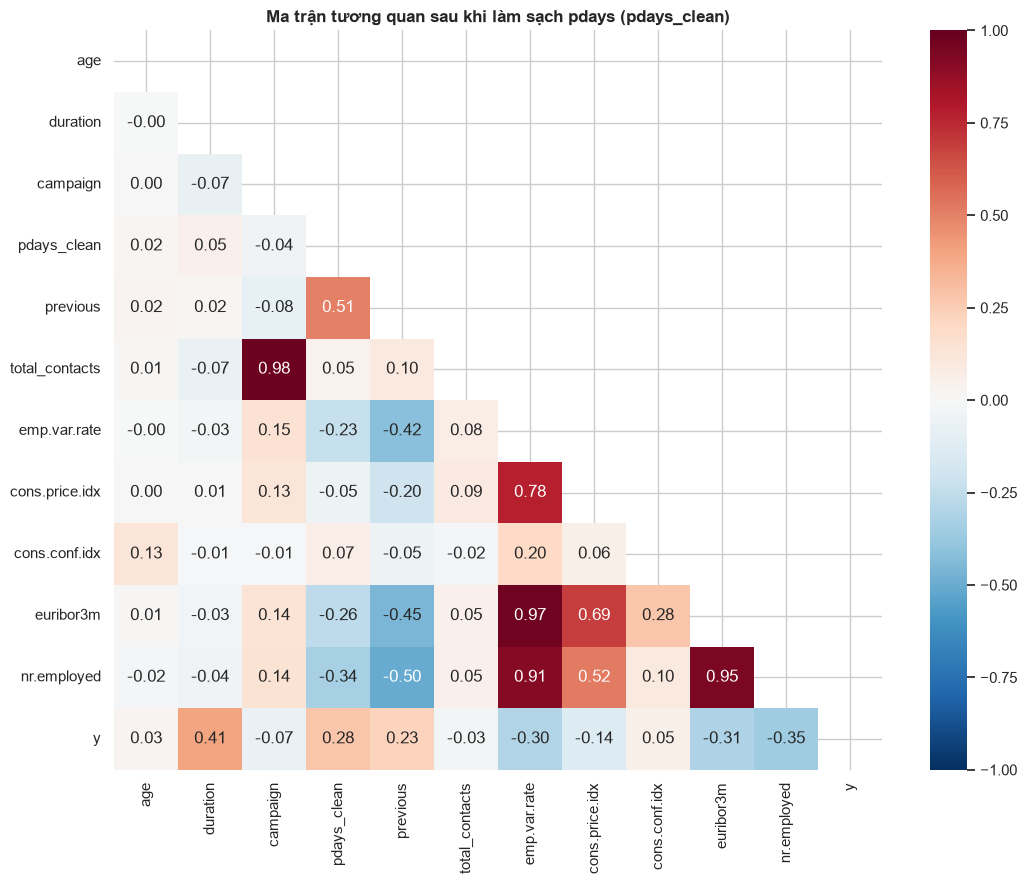

In [26]:
# --- BƯỚC 3 & 5A: LÀM SẠCH VÀ TẠO ĐẶC TRƯNG ĐÚNG NGỮ NGHĨA ---
df_feat = df_clean.copy()

# 1. Tách đúng 2 cờ từ pdays và previous (Sửa lỗi logic #1)
df_feat['was_contacted_before'] = (df_feat['previous'] > 0).astype(int)  # Đúng nghĩa: đã từng liên hệ trước đây (5.625 khách)
df_feat['has_valid_pdays'] = (df_feat['pdays'] != 999).astype(int)       # Cờ ghi nhận pdays có giá trị số ngày (1.515 khách)
df_feat['pdays_clean'] = df_feat['pdays'].replace(999, -1)
df_feat = df_feat.drop(columns=['pdays'])

# 2. Tạo tổng số lần liên hệ (giữ lại age và month gốc, không tạo age_group/month_num để tránh trùng lặp đặc trưng)
df_feat['total_contacts'] = df_feat['campaign'] + df_feat['previous']

# 3. Chuyển nhãn y sang 0/1
df_feat['y'] = (df_feat['y'] == 'yes').astype(int)

# 4. Vẽ lại ma trận tương quan sau khi làm sạch pdays = 999 (Sửa lỗi #2)
num_clean_cols = ['age', 'duration', 'campaign', 'pdays_clean', 'previous', 'total_contacts',
                  'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
plt.figure(figsize=(11, 9))
corr_clean = df_feat[num_clean_cols].corr()
mask = np.triu(np.ones_like(corr_clean, dtype=bool))
sns.heatmap(corr_clean, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Ma trận tương quan sau khi làm sạch pdays (pdays_clean)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig("../reports/figures/04b_correlation_matrix_cleaned.png", dpi=300)
plt.show()

In [27]:
import json
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

X = df_feat.drop(columns=['y'])
y = df_feat['y']

# --- PHƯƠNG ÁN 1 (BẢN CHÍNH): Chia ngẫu nhiên có phân tầng (Stratified 80/20) ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Lưu bản thô trước khi One-Hot (phục vụ TV3 test pipeline demo & TV4 kiểm tra)
X_train_raw.assign(y=y_train.values).to_parquet("../data/processed/train_raw.parquet", index=False)
X_test_raw.assign(y=y_test.values).to_parquet("../data/processed/test_raw.parquet", index=False)

# --- PHƯƠNG ÁN 2 (BẢN THỜI GIAN): 80% dòng đầu làm Train, 20% dòng cuối làm Test (Không stratify) ---
split_idx = int(len(df_feat) * 0.8)
X_train_time_raw, X_test_time_raw = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train_time, y_test_time = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()

def build_and_save(X_tr, X_te, y_tr, y_te, prefix="train", test_prefix="test",
                   include_duration=False, save_artifacts=False):
    X_tr_c = X_tr.copy()
    X_te_c = X_te.copy()
    
    if not include_duration:
        X_tr_c = X_tr_c.drop(columns=['duration'])
        X_te_c = X_te_c.drop(columns=['duration'])
        
    cat_cols = X_tr_c.select_dtypes(include=['object', 'string']).columns.tolist()
    num_cols = X_tr_c.select_dtypes(exclude=['object', 'string']).columns.tolist()
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', 'passthrough', num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
        ]
    )
    
    X_tr_trans = preprocessor.fit_transform(X_tr_c)
    X_te_trans = preprocessor.transform(X_te_c)
    
    ohe_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
    feature_names = num_cols + ohe_names
    
    df_tr_out = pd.DataFrame(X_tr_trans, columns=feature_names)
    df_te_out = pd.DataFrame(X_te_trans, columns=feature_names)
    
    # Loại bỏ cột gần như hằng số default_yes nếu tồn tại (Sửa lỗi #4)
    if 'default_yes' in df_tr_out.columns:
        df_tr_out = df_tr_out.drop(columns=['default_yes'])
        df_te_out = df_te_out.drop(columns=['default_yes'])
        feature_names.remove('default_yes')
        
    df_tr_out['y'] = y_tr.values
    df_te_out['y'] = y_te.values
    
    df_tr_out.to_parquet(f"../data/processed/{prefix}.parquet", index=False)
    df_te_out.to_parquet(f"../data/processed/{test_prefix}.parquet", index=False)
    
    # Lưu preprocessor & danh sách cột cho bản chính (phục vụ TV3 làm app/demo)
    if save_artifacts:
        joblib.dump(preprocessor, "../models/preprocessor.joblib")
        with open("../models/feature_metadata.json", "w", encoding="utf-8") as f:
            json.dump({
                "raw_input_columns": X_tr_c.columns.tolist(),
                "numeric_columns": num_cols,
                "categorical_columns": cat_cols,
                "processed_feature_columns": feature_names
            }, f, ensure_ascii=False, indent=2)
            
    print(f"✔ {prefix}.parquet ({df_tr_out.shape}) & {test_prefix}.parquet ({df_te_out.shape}) "
          f"| Train y=1: {y_tr.mean()*100:.2f}%, Test y=1: {y_te.mean()*100:.2f}%")

print("=== KẾT QUẢ XUẤT DỮ LIỆU BÀN GIAO ===")
# 1. Bản chính (Stratified, không duration) + lưu preprocessor.joblib
build_and_save(X_train_raw, X_test_raw, y_train, y_test,
               prefix="train", test_prefix="test", include_duration=False, save_artifacts=True)

# 2. Bản tham chiếu (Stratified, có duration - cho TV4)
build_and_save(X_train_raw, X_test_raw, y_train, y_test,
               prefix="train_with_duration", test_prefix="test_with_duration", include_duration=True)

# 3. Bản chia theo thời gian (80% đầu / 20% cuối, không duration - cho TV2 kiểm tra độ bền)
build_and_save(X_train_time_raw, X_test_time_raw, y_train_time, y_test_time,
               prefix="train_time", test_prefix="test_time", include_duration=False)

=== KẾT QUẢ XUẤT DỮ LIỆU BÀN GIAO ===
✔ train.parquet ((32940, 65)) & test.parquet ((8236, 65)) | Train y=1: 11.27%, Test y=1: 11.27%
✔ train_with_duration.parquet ((32940, 66)) & test_with_duration.parquet ((8236, 66)) | Train y=1: 11.27%, Test y=1: 11.27%
✔ train_time.parquet ((32940, 64)) & test_time.parquet ((8236, 64)) | Train y=1: 6.38%, Test y=1: 30.83%


In [28]:
expected_files = [
    "train.parquet", "test.parquet",
    "train_with_duration.parquet", "test_with_duration.parquet",
    "train_time.parquet", "test_time.parquet",
    "train_raw.parquet", "test_raw.parquet"
]

for fname in expected_files:
    df_chk = pd.read_parquet(f"../data/processed/{fname}")
    assert df_chk.isna().sum().sum() == 0, f"Lỗi: {fname} có NaN!"
print(f"✔ Đã kiểm tra xong {len(expected_files)} file trong data/processed/ - Không có giá trị NaN.")
print("✔ Đã lưu models/preprocessor.joblib và models/feature_metadata.json cho TV3.")

✔ Đã kiểm tra xong 8 file trong data/processed/ - Không có giá trị NaN.
✔ Đã lưu models/preprocessor.joblib và models/feature_metadata.json cho TV3.


### Xử lý rò rỉ dữ liệu với biến `duration` (Bước 4)

- **Vấn đề:** Thuộc tính `duration` ghi nhận thời lượng cuộc gọi (tính bằng giây). Trên thực tế, thông số này **chỉ được biết sau khi cuộc gọi đã kết thúc**, tức là tại thời điểm kết quả đăng ký (`y`) cũng đã được xác định (nếu `duration = 0` thì chắc chắn `y = no`; cuộc gọi càng kéo dài thì xác suất khách hàng đồng ý càng cao).
- **Hệ quả nếu giữ lại:** Việc đưa `duration` vào huấn luyện mô hình dự đoán trước khi gọi sẽ gây ra hiện tượng **rò rỉ dữ liệu từ tương lai (Target/Data Leakage)**, khiến mô hình đạt điểm số cao giả tạo trên tập kiểm thử nhưng hoàn toàn vô dụng khi triển khai thực tế để chọn danh sách khách hàng trước khi gọi.
- **Giải pháp bàn giao 2 phiên bản:**
  1. `train.parquet` & `test.parquet` (**Bản chính**): Đã loại bỏ hoàn toàn cột `duration`. Dùng để huấn luyện và đánh giá các mô hình thực tế (Decision Tree, Random Forest).
  2. `train_with_duration.parquet` & `test_with_duration.parquet` (**Bản tham chiếu**): Giữ nguyên cột `duration` trên cùng một tập phân chia Train/Test để thành viên thực hiện thí nghiệm đối chứng, định lượng mức độ sai lệch hiệu năng do Data Leakage gây ra.

In [29]:
# Kiểm tra nhanh các file bàn giao trong data/processed/
for name in ["train", "test", "train_with_duration", "test_with_duration"]:
    df_check = pd.read_parquet(f"../data/processed/{name}.parquet")
    assert df_check.isna().sum().sum() == 0, f"Lỗi: {name} chứa giá trị NaN!"
    print(f"{name}.parquet -> Shape: {df_check.shape} | Tỷ lệ y=1: {df_check['y'].mean()*100:.2f}% | NaN: 0")

print("\nTất cả file bàn giao đều hợp lệ và sẵn sàng sử dụng!")

train.parquet -> Shape: (32940, 65) | Tỷ lệ y=1: 11.27% | NaN: 0
test.parquet -> Shape: (8236, 65) | Tỷ lệ y=1: 11.27% | NaN: 0
train_with_duration.parquet -> Shape: (32940, 66) | Tỷ lệ y=1: 11.27% | NaN: 0
test_with_duration.parquet -> Shape: (8236, 66) | Tỷ lệ y=1: 11.27% | NaN: 0

Tất cả file bàn giao đều hợp lệ và sẵn sàng sử dụng!


In [30]:
# --- KIỂM TRA CHÉO TOÀN BỘ FILE BÀN GIAO TRONG data/processed/ ---
print("=== KIỂM TRA FILE BÀN GIAO TRONG data/processed/ ===")
for fname in ["train.parquet", "test.parquet", "train_with_duration.parquet", "test_with_duration.parquet"]:
    df_tmp = pd.read_parquet(f"../data/processed/{fname}")
    assert df_tmp.isna().sum().sum() == 0, f"Cảnh báo: {fname} bị dính giá trị NaN!"
    print(f"✔ {fname:<30} | Shape: {str(df_tmp.shape):<14} | Tỷ lệ y=1: {df_tmp['y'].mean()*100:.2f}%")

=== KIỂM TRA FILE BÀN GIAO TRONG data/processed/ ===
✔ train.parquet                  | Shape: (32940, 65)    | Tỷ lệ y=1: 11.27%
✔ test.parquet                   | Shape: (8236, 65)     | Tỷ lệ y=1: 11.27%
✔ train_with_duration.parquet    | Shape: (32940, 66)    | Tỷ lệ y=1: 11.27%
✔ test_with_duration.parquet     | Shape: (8236, 66)     | Tỷ lệ y=1: 11.27%
